# Serie III · Mercado — 13. Respuesta de la oferta al precio

**Pregunta 4 de la prueba:** ¿responden el área o la producción de caña de los países productores al precio del
azúcar? ¿Con qué rezago? Cuide la diferencia entre correlación y causalidad.

**Por qué es difícil.**
- **El precio es el mismo para todos los países.** Aunque hay 71 países, solo hay ~20 años de cambios de precio: la
  variación que identifica la respuesta es la del tiempo, no la de los países. Con tan pocos años, los errores
  estándar habituales prometen más precisión de la que hay.
- **El precio y la oferta se determinan juntos.** Si un año se produce más, el precio baja (causalidad inversa).
  Brasil, con cerca de la mitad de las exportaciones mundiales, mueve el precio.
- **El precio que ve cada productor no es el No. 11 en dólares.** Cuenta la moneda local, las cuotas, los precios
  internos (India, Estados Unidos, la Unión Europea) y el etanol (Brasil).

**Diseño.**
1. Panel país-año de 2000 a 2023, porque el precio de la prueba empieza en 2000. Los países son los 71 de la pregunta
   1.
2. Cambios anuales (en logaritmos) del área y de la producción contra cambios del precio de años **anteriores**. Un
   precio pasado ya estaba fijado cuando se decidió sembrar, así que no puede ser consecuencia del área de hoy.
3. **Efectos fijos por país:** cada país tiene su propio ritmo de crecimiento y se compara contra sí mismo.
4. **Placebos:** el precio del mismo año y del año siguiente. El área de hoy no debería responder a precios que
   todavía no existen; si se asocia con ellos, la relación también va al revés.
5. **Inercia:** una versión agrega los rezagos del propio crecimiento del área (ARDL), para que los rezagos del
   precio no recojan la historia del área.
6. **Prueba de permutación:** se barajan los años del precio para ver qué tan seguido sale un efecto así por azar.
   Es la prueba honesta cuando solo hay ~20 años.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from mercado_faostat import cargar_fao, panel_paises, seleccionar, es
from mercado_precio import cargar_precio
from mercado_oferta import precio_anual, panel_oferta, estimar, permutacion, jackknife_anios, agregado, nombre

RAW = ROOT / "data" / "raw" / "serie3"
FIG = ROOT / "outputs" / "figures"; TAB = ROOT / "outputs" / "tables"; MOD = ROOT / "outputs" / "models"
for d in (FIG, TAB, MOD): d.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9a9993"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
})
def guardar(fig, nombre_):
    fig.tight_layout(); fig.savefig(FIG / nombre_, bbox_inches="tight"); plt.show()

L = cargar_fao(RAW / "Production_Crops_Livestock_E_All_Data.csv")
P = panel_paises(L); SEL = seleccionar(P)
S = cargar_precio(RAW / "individual_data" / "Sugar_data.csv")
PA = precio_anual(S).loc[:2023]
D = panel_oferta(P, SEL, PA)
D = D[D.anio <= 2023].copy()
D["peso"] = D.groupby("pais").area.shift()          # área del año anterior, para ponderar por tamaño
print(f"{len(SEL)} países · precio anual {PA.index.min()}-{PA.index.max()} (2000 desde marzo)")
display(PA.round(2).to_frame("¢/lb").T)

71 países · precio anual 2000-2023 (2000 desde marzo)


anio,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
¢/lb,8.68,8.36,6.39,6.96,7.4,9.99,14.63,9.9,12.1,17.98,22.28,27.07,21.59,17.47,16.34,13.12,18.16,15.78,12.24,12.34,12.87,17.87,18.82,24.09


## 1. Primera mirada: el mundo en conjunto

Antes del panel, la suma de los 71 países. Si la oferta responde con rezago, el crecimiento del área de cada año
debería parecerse al cambio del precio de dos o tres años antes.

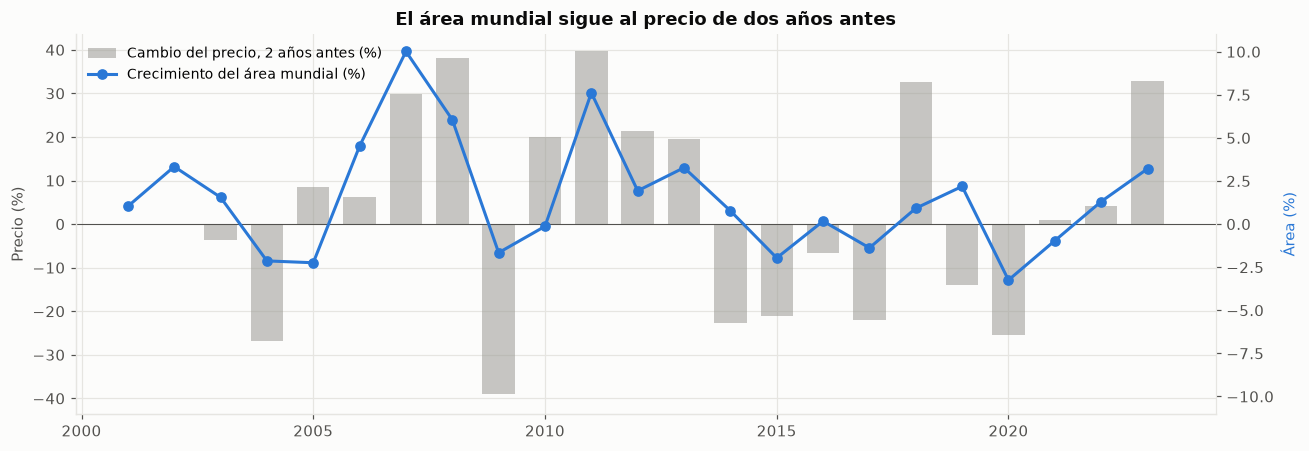

Correlación entre el crecimiento del área mundial y el cambio del precio 2 años antes: 0.72


In [2]:
W = P[P.pais.isin(SEL) & (P.anio >= 2000)].groupby("anio")[["area", "prod"]].sum()
dla_w = 100 * np.log(W.area).diff(); dlp = 100 * np.log(PA).diff()
fig, ax = plt.subplots(figsize=(12, 4.2))
b2 = dlp.shift(2).loc[2002:2023]
ax.bar(b2.index, b2.values, color=GRIS, alpha=0.55, width=0.7, label="Cambio del precio, 2 años antes (%)")
ax2 = ax.twinx()
ax2.plot(dla_w.index, dla_w.values, color=AZUL, marker="o", lw=2, label="Crecimiento del área mundial (%)")
ax.axhline(0, color=TINTA2, lw=0.7); ax.set_ylabel("Precio (%)"); ax2.set_ylabel("Área (%)", color=AZUL)
lim1 = 1.1 * np.nanmax(np.abs(b2.values)); lim2 = 1.1 * np.nanmax(np.abs(dla_w.values))
ax.set_ylim(-lim1, lim1); ax2.set_ylim(-lim2, lim2)          # mismo cero en los dos ejes
ax2.spines["right"].set_visible(True); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper left", fontsize=9)
ax.set_title("El área mundial sigue al precio de dos años antes")
guardar(fig, "serie3_10_oferta_agregada.png")
c = pd.concat([dla_w, dlp.shift(2)], axis=1).dropna().corr().iloc[0, 1]
print(f"Correlación entre el crecimiento del área mundial y el cambio del precio 2 años antes: {c:.2f}")

Las alzas de 2005-2006 fueron seguidas por la mayor expansión de área de la serie (2007-2008). La caída de 2007 fue
seguida por un área estancada en 2009-2010, y el alza de 2009, por la expansión de 2011. La correlación es 0.72, pero
con 21 puntos: es sugerente, todavía no es evidencia. El panel permite separar el ritmo propio de cada país y probar
los placebos.

## 2. Panel con efectos fijos: ¿con qué rezago?

Se estima el cambio del área contra el cambio del precio del año siguiente (placebo), del mismo año y de 1 a 4 años
antes. Cada coeficiente es una **elasticidad**: 0.05 significa que un precio 10 % más alto se asocia con 0.5 % más área
ese año.

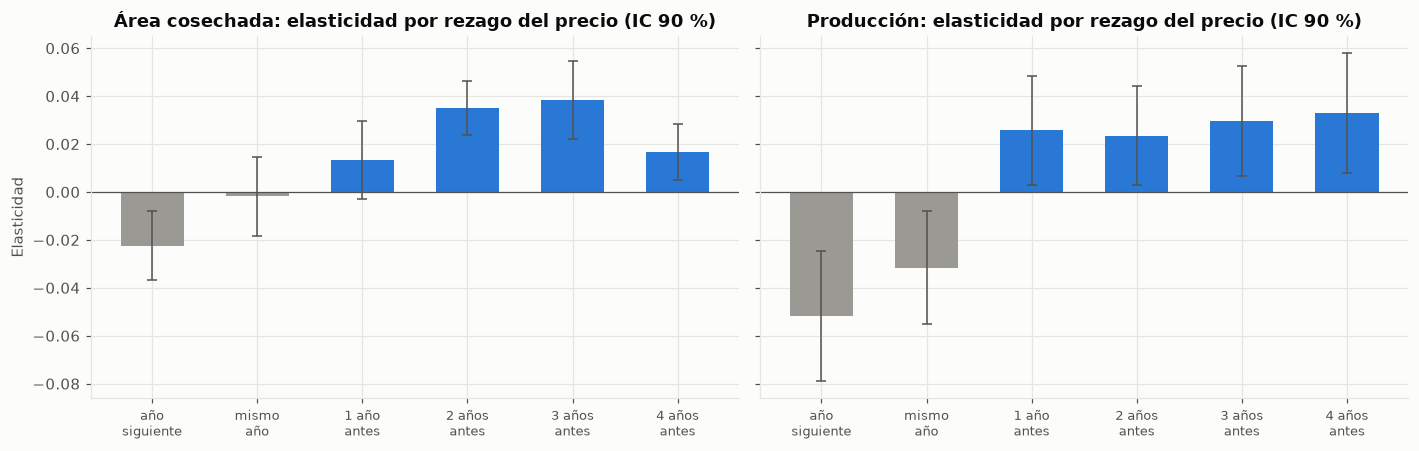

,dla coef,dla p,dlq coef,dlq p
año siguiente (placebo),-0.022,0.011,-0.052,0.002
mismo año,-0.002,0.851,-0.032,0.028
1 año antes,0.013,0.178,0.026,0.062
2 años antes,0.035,0.000,0.024,0.060
3 años antes,0.038,0.000,0.030,0.035
4 años antes,0.017,0.018,0.033,0.030


In [3]:
LAGS_PERFIL = [-1, 0, 1, 2, 3, 4]
perf = {dep: estimar(D, dep, LAGS_PERFIL) for dep in ["dla", "dlq"]}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
etiq = ["año\nsiguiente", "mismo\naño", "1 año\nantes", "2 años\nantes", "3 años\nantes", "4 años\nantes"]
for a, (dep, tit) in zip(ax, [("dla", "Área cosechada"), ("dlq", "Producción")]):
    r = perf[dep]; x = np.arange(len(LAGS_PERFIL))
    col = [GRIS if k <= 0 else AZUL for k in LAGS_PERFIL]
    a.bar(x, r["coef"].values, color=col, width=0.6)
    a.errorbar(x, r["coef"].values, yerr=1.645 * r["se"].values, fmt="none", ecolor=TINTA2, capsize=3, lw=1)
    a.axhline(0, color=TINTA2, lw=0.8); a.set_xticks(x); a.set_xticklabels(etiq, fontsize=8.5)
    a.set_title(f"{tit}: elasticidad por rezago del precio (IC 90 %)")
ax[0].set_ylabel("Elasticidad")
guardar(fig, "serie3_11_oferta_rezagos.png")
tab = pd.DataFrame({f"{dep} coef": perf[dep]["coef"] for dep in perf} | {f"{dep} p": perf[dep]["p"] for dep in perf})
tab.index = ["año siguiente (placebo)", "mismo año", "1 año antes", "2 años antes", "3 años antes", "4 años antes"]
display(tab[["dla coef", "dla p", "dlq coef", "dlq p"]].round(3))

**Lectura.**
- **Área:**
  - El precio del mismo año no se asocia con el área (0.00).
  - **El placebo falla.** El precio del año siguiente se asocia negativamente con el área de hoy (−0.02, p ≈ 0.01).
    La lectura más simple es que la flecha también va al revés: más área hoy, más azúcar después y un precio más bajo
    el año siguiente. Es el signo que se espera de esa retroalimentación. Una causa común que anticipara alzas daría
    el signo contrario.
  - La respuesta al precio aparece **a los 2-3 años** (0.035 y 0.038) y queda algo a los 4 (0.017). Es pequeña.
- **Producción:** el precio del **mismo año** y el del **año siguiente** se asocian negativamente con la producción.
  Es compatible con que un año de mucha producción baje el precio (causalidad inversa), aunque también con causas
  comunes. Por eso la respuesta de la oferta solo se mide con precios **pasados**.
- **El rezago tiene sentido agronómico.** La caña es perenne: se siembra una vez y se cosecha 5-6 años (soca). Ampliar
  área requiere tierra, semilla y capacidad de molienda, y la primera cosecha llega 12-18 meses después de sembrar.
- Los p de esta tabla usan errores agrupados por año, que con ~20 años son optimistas. La prueba exigente está en la
  sección 3.

### 2.1 ¿Los rezagos son eco de la inercia del área?
Que el placebo falle tiene una consecuencia. Si el área tiene inercia y además mueve el precio, los precios pasados
quedan correlacionados con el área pasada, y los rezagos podrían estar midiendo esa historia y no una respuesta al
precio. Para separarlo se agregan los dos rezagos del **propio crecimiento del área** (modelo ARDL).

In [4]:
ardl = {"simple (−1 a 4)": estimar(D, "dla", LAGS_PERFIL), "con inercia (−1 a 4)": estimar(D, "dla", LAGS_PERFIL, propios=2),
        "con inercia (−1 a 3)": estimar(D, "dla", [-1, 0, 1, 2, 3], propios=2)}
T2 = pd.DataFrame({f"{k} · {c}": (v["coef"] if c == "coef" else v["p"]) for k, v in ardl.items() for c in ["coef", "p"]})
T2.index = [{"dlpm1": "año siguiente (placebo)", "dlp0": "mismo año"}.get(i, f"{i[-1]} año(s) antes") for i in T2.index]
display(T2.round(3))
print("Inercia propia (con inercia, −1 a 4):", ardl["con inercia (−1 a 4)"]["propios"].round(3).to_dict(),
      "· años:", {k: v["anios"] for k, v in ardl.items()})

,simple (−1 a 4) · coef,simple (−1 a 4) · p,con inercia (−1 a 4) · coef,con inercia (−1 a 4) · p,con inercia (−1 a 3) · coef,con inercia (−1 a 3) · p
mismo año,-0.002,0.851,-0.001,0.900,-0.010,0.348
1 año(s) antes,0.013,0.178,0.009,0.352,0.009,0.435
2 año(s) antes,0.035,0.000,0.038,0.000,0.032,0.000
3 año(s) antes,0.038,0.000,0.043,0.000,0.046,0.000
4 año(s) antes,0.017,0.018,0.027,0.001,NaN,NaN
año siguiente (placebo),-0.022,0.011,-0.024,0.005,-0.013,0.188


Inercia propia (con inercia, −1 a 4): {'dla_l1': -0.136, 'dla_l2': -0.105} · años: {'simple (−1 a 4)': 18, 'con inercia (−1 a 4)': 18, 'con inercia (−1 a 3)': 19}


- **La respuesta a 2-3 años no es eco de la inercia.** Con los rezagos del propio crecimiento del área, los
  coeficientes de 2 y 3 años se mantienen o suben un poco. La inercia es negativa: un año de mucho crecimiento suele
  seguirse de uno más lento.
- **El placebo depende de la muestra.** Con 18 años (perfil de −1 a 4) sigue negativo y significativo. Con 19 años
  (perfil de −1 a 3) baja a −0.013 y deja de serlo. La retroalimentación de la oferta al precio no desaparece del
  todo.

## 3. ¿Es real o es azar?

El modelo principal usa los rezagos de 1 a 3 años, fijados en la exploración inicial antes de ver el perfil, con y sin
la inercia propia. La **elasticidad acumulada** (la suma) dice cuánto más área hay 3 años después de un alza del
precio. La prueba exigente es la de **permutación**: se barajan los años del precio 2,000 veces y se cuenta qué tan
seguido sale una suma así por azar.

In [5]:
LAGS = [1, 2, 3]
base = {dep: estimar(D, dep, LAGS) for dep in ["dla", "dlq"]}
for dep, r in base.items():
    print(f"{dep}: elasticidad acumulada {r['suma']:.3f} (error agrupado por año {r['se_suma']:.3f}, t = {r['suma'] / r['se_suma']:.1f}) · "
          f"{r['n']} observaciones, {r['paises']} países, {r['anios']} años")
PERM = {
    "Área, 1-3 años": permutacion(D, PA, "dla", LAGS),
    "Área, 1-3 años, con inercia": permutacion(D, PA, "dla", LAGS, propios=2),
    "Área, 1-4 años": permutacion(D, PA, "dla", [1, 2, 3, 4]),
    "Producción, 1-3 años, con inercia": permutacion(D, PA, "dlq", LAGS, propios=2),
    "Área ponderada por tamaño, con inercia (exploratorio)": permutacion(D.dropna(subset=["peso"]), PA, "dla", LAGS, propios=2, peso="peso"),
}
display(pd.DataFrame(PERM).T.round(3))

dla: elasticidad acumulada 0.081 (error agrupado por año 0.026, t = 3.1) · 1420 observaciones, 71 países, 20 años
dlq: elasticidad acumulada 0.085 (error agrupado por año 0.034, t = 2.5) · 1420 observaciones, 71 países, 20 años


,suma,p_una_cola,p_dos_colas,nulo_p95
"Área, 1-3 años",0.081,0.054,0.100,0.082
"Área, 1-3 años, con inercia",0.081,0.080,0.154,0.092
"Área, 1-4 años",0.088,0.110,0.215,0.108
"Producción, 1-3 años, con inercia",0.070,0.124,0.260,0.100
"Área ponderada por tamaño, con inercia (exploratorio)",0.170,0.014,0.026,0.129


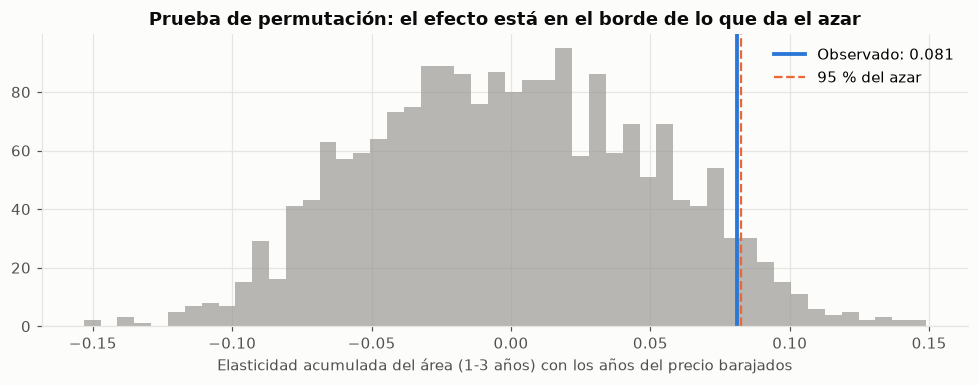

Con inercia, quitando un año a la vez, la elasticidad acumulada va de 0.066 (sin 2007) a 0.096 (sin 2016)
Peso de cada país en la versión ponderada: {'Brazil': '36 %', 'India': '19 %', 'China, mainland': '6 %', 'Thailand': '5 %'}


In [6]:
rng = np.random.default_rng(20261019)
dlp_ = np.log(PA).diff().dropna(); nul = []
for _ in range(2000):
    sim = pd.Series(rng.permutation(dlp_.values), index=dlp_.index); Dp = D.copy()
    for k in LAGS: Dp[nombre(k)] = Dp.anio.map(sim.shift(k))
    nul.append(estimar(Dp, "dla", LAGS)["suma"])
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(nul, bins=50, color=GRIS, alpha=0.7)
ax.axvline(base["dla"]["suma"], color=AZUL, lw=2.5, label=f"Observado: {base['dla']['suma']:.3f}")
ax.axvline(np.percentile(nul, 95), color=NARANJA, ls="--", lw=1.5, label="95 % del azar")
ax.set_xlabel("Elasticidad acumulada del área (1-3 años) con los años del precio barajados")
ax.set_title("Prueba de permutación: el efecto está en el borde de lo que da el azar"); ax.legend(frameon=False)
guardar(fig, "serie3_12_oferta_permutacion.png")
JK = jackknife_anios(D, "dla", LAGS, propios=2)
w = D[D.anio >= 2003].groupby("pais").peso.sum(); w = (w / w.sum()).sort_values(ascending=False)
print(f"Con inercia, quitando un año a la vez, la elasticidad acumulada va de {JK.min():.3f} (sin {JK.idxmin()}) a {JK.max():.3f} (sin {JK.idxmax()})")
print("Peso de cada país en la versión ponderada:", {k: f"{100 * v:.0f} %" for k, v in w.head(4).items()})

**Lectura.**
- Con los errores habituales (agrupados por año), la elasticidad acumulada del área (0.08) parece muy significativa
  (t ≈ 3).
- **La prueba de permutación es más exigente y más honesta.** Una suma así o mayor sale por azar en ~5 % de los casos
  sin inercia y en ~8 % con inercia (a una cola); a dos colas, entre 10 % y 15 %. Si se suma también el rezago de 4
  años, sube a ~11 %. **La evidencia del panel completo está en el borde y depende de la especificación.**
- La versión **ponderada por tamaño** da un efecto mayor (~0.17) que sí pasa la prueba (p ≈ 0.01). Pero es
  **exploratoria**: se miró después de ver el panel, y Brasil e India pesan más de la mitad, así que en la práctica son
  dos series de 20 años.
- No depende de un año en particular: con inercia y quitando cualquier año, la elasticidad queda entre 0.07 y 0.10.
- **Magnitud:** un precio 10 % más alto se asocia con ~0.8 % más área tres años después. La oferta de caña es muy
  **inelástica** en el corto plazo.

## 4. ¿Quién responde?

In [7]:
grandes = ["Brazil", "India", "China, mainland", "Thailand"]
specs = {
    "Con inercia (71 países, error agrupado por año)": estimar(D, "dla", LAGS, propios=2),
    "Con inercia, error Driscoll-Kraay": estimar(D, "dla", LAGS, propios=2, cov="dk"),
    "Con inercia, solo datos oficiales": estimar(D[D.oficial], "dla", LAGS, propios=2),
    "Con inercia, sin Brasil, India, China y Tailandia": estimar(D[~D.pais.isin(grandes)], "dla", LAGS, propios=2),
    "Con inercia, ponderado por área (exploratorio)": estimar(D.dropna(subset=["peso"]), "dla", LAGS, propios=2, peso="peso"),
}
rob = pd.DataFrame({k: {"1 año": v["coef"].iloc[0], "2 años": v["coef"].iloc[1], "3 años": v["coef"].iloc[2],
                        "acumulada": v["suma"], "error": v["se_suma"], "n": v["n"]} for k, v in specs.items()}).T
AG = agregado(P, SEL, PA)
rob.loc["Agregado mundial (1 serie, 20 años, HAC)"] = [*AG["dla"]["coef"].values, AG["dla"]["suma"], AG["dla"]["se_suma"], AG["dla"]["n"]]
display(rob.round(3))

,1 año,2 años,3 años,acumulada,error,n
"Con inercia (71 países, error agrupado por año)",0.012,0.019,0.050,0.081,0.026,1420.0
"Con inercia, error Driscoll-Kraay",0.012,0.019,0.050,0.081,0.027,1420.0
"Con inercia, solo datos oficiales",0.002,0.029,0.066,0.097,0.040,848.0
"Con inercia, sin Brasil, India, China y Tailandia",0.012,0.010,0.048,0.071,0.026,1340.0
"Con inercia, ponderado por área (exploratorio)",0.010,0.091,0.068,0.170,0.041,1420.0
"Agregado mundial (1 serie, 20 años, HAC)",0.019,0.099,0.066,0.184,0.049,20.0


**Lectura.**
- La elasticidad acumulada se mantiene con otros errores, solo con datos oficiales y sin los cuatro gigantes. El
  patrón es siempre el mismo: casi nada al año y la respuesta a los 2-3 años.
- Ponderada por área y en la serie mundial, la respuesta es mayor y se concentra a los **2 años**. Es coherente con que
  Brasil y otros grandes tengan frontera agrícola y capital para expandirse rápido, y los chicos (con cuotas, tierra
  limitada o precios internos) menos. Pero es exploratorio y descansa casi todo en dos países.
- Aun en los grandes, la oferta es inelástica: un precio 10 % más alto se asocia con ~2 % más área en dos o tres años.

## 5. Correlación o causalidad

Lo que se estimó es una **asociación con precios pasados**, controlada por el ritmo propio y la inercia de cada país.
Eso no alcanza para hablar de causalidad:

- **La relación va en los dos sentidos.** El placebo del año siguiente sale negativo: la oferta también mueve el
  precio. Usar precios pasados y controlar la inercia reduce ese problema, pero no lo elimina.
- **Causas comunes.** Un alza del petróleo sube el precio del azúcar (vía etanol) y a la vez hace más rentable la caña
  para etanol en Brasil. Una devaluación del real abarata el azúcar brasileño y a la vez estimula su siembra. Estas
  causas mueven el precio y el área sin que una cause a la otra. Los efectos fijos por país no las quitan, y no se
  pueden usar efectos fijos por año porque absorberían el precio.
- **El precio que importa es otro.** Cada productor responde a su precio en moneda local, con cuotas e impuestos, y en
  términos reales. Aquí se usa el No. 11 nominal en dólares; eso tiende a **subestimar** la respuesta.
- **Un intento de experimento natural.** Las sequías y heladas en Brasil mueven el precio mundial sin afectar
  directamente la siembra en otros países. Serían un instrumento ideal. Se probó con el cambio del rendimiento de
  Brasil:

In [8]:
B = P[P.pais == "Brazil"].set_index("anio")
x = pd.concat([np.log(PA).diff().rename("dlp"), np.log(B.rend).diff().rename("rend_brasil")], axis=1).dropna()
fs = sm.OLS(x.dlp, sm.add_constant(x.rend_brasil)).fit()
print(f"Primera etapa: cambio del precio contra el cambio del rendimiento de Brasil · coef {fs.params['rend_brasil']:.2f}, F = {fs.fvalue:.2f}, n = {int(fs.nobs)}")

Primera etapa: cambio del precio contra el cambio del rendimiento de Brasil · coef -0.82, F = 0.23, n = 23


El rendimiento anual de Brasil casi no predice el precio del año (F ≈ 0.2; se necesita F > 10). Hay dos razones
probables: el año calendario no coincide con la zafra brasileña, y el precio reacciona a las **expectativas** de
cosecha antes que al dato final. El instrumento es débil y no sirve para afirmar causalidad. Con datos mensuales de
avance de zafra (UNICA) o de clima, este diseño sí sería viable.

**Conclusión sobre causalidad.**
- **Lo robusto** es una **asociación rezagada** entre el precio de 2-3 años antes y el área. Sobrevive a controlar la
  inercia, a quitar cualquier año, a usar solo datos oficiales y a sacar a los gigantes. Además es coherente con la
  agronomía.
- **Lo débil** es la evidencia causal:
  - el placebo falla en algunas muestras;
  - la significancia del panel está en el borde (p ≈ 0.05-0.08 a una cola) y depende de cuántos rezagos se usen;
  - el efecto mayor de los grandes productores es exploratorio;
  - no se pueden separar las causas comunes.
- **La respuesta honesta a la pregunta:** el área parece responder al precio, poco y con 2-3 años de rezago. Con estos
  datos no se puede afirmar que sea causal.

## 6. ¿Y Guatemala?

Con 20 años, una regresión para un solo país no tiene poder estadístico. Además, el área de Guatemala en 2017-2023 es
estimada o imputada por FAO (pregunta 1), así que su respuesta reciente no se puede medir con esta base. Lo que sí se
puede decir es descriptivo:

In [9]:
g = D[D.pais == "Guatemala"].set_index("anio")
gt = pd.DataFrame({"área (miles de ha)": g.area / 1e3, "bandera del área": g.f_area, "precio 2 años antes (¢/lb)": PA.shift(2).reindex(g.index)}).loc[2004:2023]
display(gt.round(1).T)

anio,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
área (miles de ha),184.9,184.9,188.7,215.7,215.7,233.2,234.6,245.2,255.9,261.1,265.6,267.9,259.8,252.0,268.4,277.8,246.6,223.8,224.4,227.2
bandera del área,A,A,A,A,A,A,A,A,A,A,A,A,A,E,E,I,I,I,I,I
precio 2 años antes (¢/lb),6.4,7.0,7.4,10.0,14.6,9.9,12.1,18.0,22.3,27.1,21.6,17.5,16.3,13.1,18.2,15.8,12.2,12.3,12.9,17.9


El área de Guatemala creció de 2004 a 2015, acompañando el ciclo de precios altos de 2009-2016. Desde 2017, la base ya
no la mide: son cifras estimadas o imputadas. Para el ingenio, la respuesta relevante no es la de Guatemala (que ya
conoce su propia historia), sino **la del mundo**: cómo reaccionan Brasil y los demás grandes cuando el precio sube.

In [10]:
resumen = {
    "paises": len(SEL), "anios_precio": [int(PA.index.min()), int(PA.index.max())],
    "perfil": {dep: {"coef": perf[dep]["coef"].round(4).to_dict(), "p": perf[dep]["p"].round(4).to_dict()} for dep in perf},
    "base": {dep: {"suma": base[dep]["suma"], "se": base[dep]["se_suma"], "n": base[dep]["n"]} for dep in base},
    "permutacion": PERM, "jackknife": [float(JK.min()), float(JK.max())],
    "ardl": {k: {"coef": v["coef"].round(4).to_dict(), "p": v["p"].round(4).to_dict(), "anios": v["anios"]} for k, v in ardl.items()},
    "robustez": rob.round(4).to_dict(orient="index"), "primera_etapa_F": float(fs.fvalue),
    "corr_area_mundial_precio_2": float(c),
}
(TAB / "serie3_resumen_p4.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=1, default=float), encoding="utf-8")
D.drop(columns=["peso"]).to_csv(TAB / "serie3_panel_oferta.csv", index=False)
print("ok")

ok


## Evaluación gerencial

**Qué significa para el ingenio.**
- La oferta mundial de caña **parece reaccionar al precio, pero poco y tarde**. Un alza de 10 % se asocia con ~0.8 %
  más área tres años después. En los grandes productores es ~2 %, concentrado a los dos años, pero ese dato es
  exploratorio.
- **La relación va en los dos sentidos:** más producción se asocia con precios más bajos el mismo año y el siguiente.
- Esto **no** permite pronosticar el precio: las preguntas 2 y 3 muestran que no hay ciclos aprovechables. Lo que dice
  es que **la expansión de los competidores llega con 2-3 años de rezago**.

**Decisión recomendada.**
1. **No expandir área por un precio alto de hoy.** Una expansión tarda años en producir y es cara de revertir en un
   cultivo perenne. Para cuando esa caña se coseche, el precio puede ser otro y la respuesta de los competidores ya
   habrá llegado. Las expansiones deberían evaluarse con escenarios de precio conservadores, no con el pico.
2. **Vigilar a Brasil** (avance de zafra, mezcla azúcar-etanol, real) como indicador adelantado de oferta.
3. En períodos de precio alto, **aprovecharlo con fijaciones de mediano plazo**. Es una decisión de gestión de
   riesgo, no un pronóstico de caída.

**Impacto estimado.** Directo, ninguno. Indirecto: evita decisiones de inversión en área calibradas con un precio
excepcional, que son las más caras de revertir.

**Riesgos.**
- Solo hay ~20 años de precio:
  - en el panel completo la significancia está en el borde (permutación p ≈ 0.05-0.08 a una cola);
  - depende de cuántos rezagos se usen;
  - el placebo falla en algunas muestras.
- El efecto mayor en los grandes productores es exploratorio y descansa casi todo en Brasil y la India.
- El precio es el No. 11 nominal en dólares, no el que recibe cada país. La respuesta real probablemente es mayor que
  la medida.
- Hay causas comunes (petróleo, tipo de cambio, políticas) que no se pueden separar con estos datos.

**Nivel de certeza.**
- **Media-baja:** en que la relación sea causal y en su magnitud exacta.
- **Media:** en el rezago de 2-3 años. Sobrevive a controlar la inercia, a quitar cualquier año y a usar solo datos
  oficiales, y es coherente con la agronomía.
- **Media:** en la asociación negativa entre la producción y el precio del mismo año (asociación, no causa
  demostrada).
- **Alta:** en que la respuesta es inelástica. Aun con el límite superior del intervalo, un alza de 10 % mueve el
  área en pocos puntos porcentuales.